# Tarea 2: Inteligencia Artificial
**Estudiantes:** Laura Ruidiaz y Angelo Maiale
**Asignación:** Desarrollo de los Puntos 1 (Regresión Lineal y Sobreajuste), 2, 3 y 4 (Ridge vs. Lasso)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 1. Cargar el dataset desde la carpeta data/
df = pd.read_csv("data/dataset.csv")
print("--- Dimensiones originales del Dataset ---")
print(df.shape)
print("\n--- Primeras filas ---")
print(df.head())

--- Dimensiones originales del Dataset ---
(8128, 12)

--- Primeras filas ---
                           name  year  selling_price  km_driven    fuel  \
0        Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1  Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2      Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3     Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4        Maruti Swift VXI BSIII  2007         130000     120000  Petrol   

  seller_type transmission         owner  mileage(km/ltr/kg)  engine  \
0  Individual       Manual   First Owner               23.40  1248.0   
1  Individual       Manual  Second Owner               21.14  1498.0   
2  Individual       Manual   Third Owner               17.70  1497.0   
3  Individual       Manual   First Owner               23.00  1396.0   
4  Individual       Manual   First Owner               16.10  1298.0   

  max_power  seats  
0        74    5.

## Punto 1: Análisis Exploratorio, Limpieza y Forzado de Sobreajuste (4 Puntos)
En este punto limpiamos el dataset, aseguramos tener al menos 8 características cuantitativas y forzamos el sobreajuste utilizando un conjunto de entrenamiento pequeño combinado con transformaciones polinómicas de grado 3.

In [2]:
# Limpieza de valores nulos
df = df.dropna().copy()

# Asegurar que max_power sea numérico
df['max_power'] = pd.to_numeric(df['max_power'], errors='coerce')
df = df.dropna().copy()

# Crear features cuantitativas adicionales para cumplir con el requisito de al menos 8 variables numéricas
df['km_per_year'] = df['km_driven'] / (2026 - df['year'] + 1)
df['engine_power_ratio'] = df['engine'] / (df['max_power'] + 1e-5)

# Definir features predictoras (8 cuantitativas) y el target continuo (selling_price)
feature_cols = ['year', 'km_driven', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats', 'km_per_year', 'engine_power_ratio']
X = df[feature_cols].values
y = df['selling_price'].values

# Split con un conjunto de entrenamiento muy pequeño para forzar over اینکه / sobreajuste
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=35, random_state=42)

# Expandir características con PolynomialFeatures (grado 3) para disparar la complejidad
poly = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Entrenar Regresión Lineal de sklearn
lr = LinearRegression()
lr.fit(X_train_poly, y_train)

# Calcular RMSEs
rmse_train_p1 = np.sqrt(mean_squared_error(y_train, lr.predict(X_train_poly)))
rmse_test_p1 = np.sqrt(mean_squared_error(y_test, lr.predict(X_test_poly)))

print("=== RESULTADOS PUNTO 1 ===")
print(f"RMSE de Entrenamiento (Overfitting): {rmse_train_p1:.4f}")
print(f"RMSE de Prueba (Test): {rmse_test_p1:.4f}")

=== RESULTADOS PUNTO 1 ===
RMSE de Entrenamiento (Overfitting): 471493.4479
RMSE de Prueba (Test): 219252791.9994


## Punto 4: Ridge vs. Lasso y Análisis Geométrico (3 Puntos)
Aquí estandarizamos las características, encontramos los hiperparámetros óptimos (alpha) para ambos modelos usando GridSearchCV, comparamos sus coeficientes y analizamos por qué Lasso anula coeficientes a cero exacto.

In [3]:
# Estandarizar features (ajustado solo con train para evitar data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

alphas = np.logspace(-4, 4, 50)

# GridSearchCV para Ridge
ridge_cv = GridSearchCV(Ridge(), {'alpha': alphas}, scoring='neg_root_mean_squared_error', cv=5)
ridge_cv.fit(X_train_scaled, y_train)
best_ridge = ridge_cv.best_estimator_

# GridSearchCV para Lasso
lasso_cv = GridSearchCV(Lasso(max_iter=20000), {'alpha': alphas}, scoring='neg_root_mean_squared_error', cv=5)
lasso_cv.fit(X_train_scaled, y_train)
best_lasso = lasso_cv.best_estimator_

print("=== MEJORES HIPERPARÁMETROS ===")
print(f"Mejor Alpha (Ridge): {ridge_cv.best_params_['alpha']:.4f}")
print(f"Mejor Alpha (Lasso): {lasso_cv.best_params_['alpha']:.4f}")

# Tabla comparativa de coeficientes
coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Ridge Coef': best_ridge.coef_,
    'Lasso Coef': best_lasso.coef_
})
print("\n--- Tabla Comparativa de Coeficientes ---")
print(coef_df)

# Conteo de ceros en Lasso
zeros_lasso = np.sum(best_lasso.coef_ == 0)
print(f"\nCoeficientes llevados exactamente a cero por Lasso: {zeros_lasso}")

=== MEJORES HIPERPARÁMETROS ===
Mejor Alpha (Ridge): 35.5648
Mejor Alpha (Lasso): 10000.0000

--- Tabla Comparativa de Coeficientes ---
              Feature     Ridge Coef     Lasso Coef
0                year  132505.648175  268976.176621
1           km_driven  -79297.290332      -0.000000
2  mileage(km/ltr/kg)  -52442.853810  -64870.562071
3              engine   91259.747263      -0.000000
4           max_power  118773.430762  253614.213446
5               seats  107873.188083  203087.191104
6         km_per_year  -35057.299000 -117540.602634
7  engine_power_ratio  -60600.644724  -71778.620781

Coeficientes llevados exactamente a cero por Lasso: 2


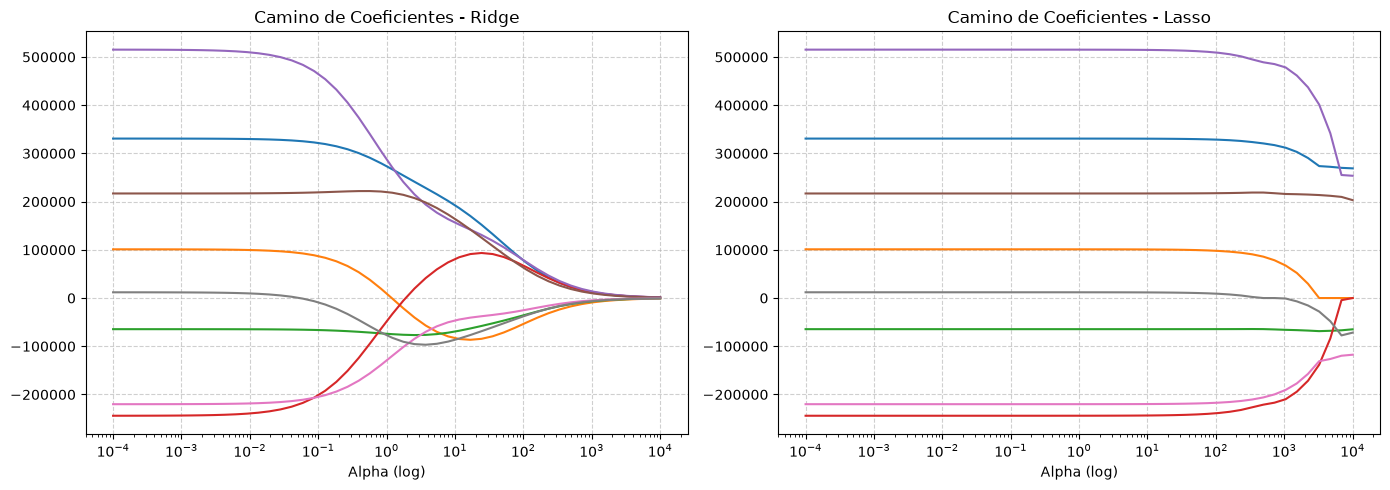

In [4]:
# Gráfica de los caminos de coeficientes para Ridge y Lasso
ridge_coefs, lasso_coefs = [], []

for a in alphas:
    r = Ridge(alpha=a).fit(X_train_scaled, y_train)
    l = Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train)
    ridge_coefs.append(r.coef_)
    lasso_coefs.append(l.coef_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ridge Path
axes[0].plot(alphas, ridge_coefs)
axes[0].set_xscale('log')
axes[0].set_title('Camino de Coeficientes - Ridge')
axes[0].set_xlabel('Alpha (log)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Lasso Path
axes[1].plot(alphas, lasso_coefs)
axes[1].set_xscale('log')
axes[1].set_title('Camino de Coeficientes - Lasso')
axes[1].set_xlabel('Alpha (log)')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()